In [1]:
# Cell 1: import library
import os, cv2, torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from pathlib import Path
from PIL import Image
import torch.nn as nn 
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

In [ ]:
# Cell 2:  setups paths
# Paths 
PROCESSED_DIR = Path("../data/processed")
MODLES_DIR = Path("../models/classification")
RAW_DATA_DIR = Path("../data/raw/data1a")
FIGURES_DIR = Path("../reports/figures/explainability")
FIGURES_DIR.mkdir(parents=True, exist_ok= True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the Chmapion Model(ResNet18 Fine-Tuned)
model = models.resnet18(weights=None)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model.load_state_dict(torch.load(MODLES_DIR / "exp03_resnet18_finetuned.pth", weights_only=True))
model = model.to(device)
model.eval()


# Trnasforms (must match with Notebook 05)
val_test_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print(f"Model loaded on {device}")

Model loaded on cuda


In [3]:
# Cell 3: Grad-CAM Implementation
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Register hooks
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx = 1):
        # Ensure gradients are zeroed
        self.model.zero_grad()

        # Forward pass
        output = self.model(input_tensor)

        # Backward pass for the specific class (1 = damaged)
        target = output[0, class_idx]
        target.backward()

        # Pool the gradients (Global Average Pooling)
        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)

        # Weighted sum of feature maps
        cam = torch.sum(weights * self.activations, dim=1).squeeze()

        # Apply ReLU (only care about features positively influence "damaged")
        cam = torch.relu(cam)

        # Normalize between 0 and 1
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam.cpu().numpy()


# Initialize Grad-CAM on the last block of ResNet18
grad_cam = GradCAM(model, model.layer4[-1])
print("Grad-CAM initialized on model.layer4[-1].")
        

Grad-CAM initialized on model.layer4[-1].


In [6]:
# Cell 4: Load Data and Predicitons 
# 1. Recreate the test loader
class CarDamageDataset(torch.utils.data.Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.root_dir / self.df.loc[idx, "image_path"]
        label = self.df.loc[idx, "target"]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label


df_test = pd.read_csv(PROCESSED_DIR / "test_split.csv")
test_loader = DataLoader(CarDamageDataset(df_test, RAW_DATA_DIR, val_test_transforms), batch_size=32, shuffle=False)

# 2. Get predictions
all_probs, all_labels = [], []
with torch.no_grad():
    for images, labels, in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())


df_test["prob_damaged"] = all_probs
df_test["pred_05"] = (df_test["prob_damaged"] >= 0.5).astype(int)

# 3. Create subsets for the 4 categories
# A. Correct Damaged
correct_damaged = df_test[(df_test["target"] == 1) & (df_test["pred_05"] == 1)]

# B. Correct Whole
correct_whole = df_test[(df_test["target"] == 0) & (df_test["pred_05"] == 0)]

# C. False Negatives (Missed Damage)
false_negatives = df_test[(df_test["target"] == 1) & (df_test["pred_05"] == 0)]

# D. False Positives (Small Whole cars predicted as Damaged)
false_positives = df_test[(df_test["target"] == 0) & (df_test["pred_05"] == 1)]


print(f"Correct Damaged: {len(correct_damaged)}")
print(f"Correct Whole: {len(correct_whole)}")
print(f"False Negatives: {len(false_negatives)}")
print(f"False Positives: {len(false_positives)}")

print("\nData and subsets ready.")


Correct Damaged: 166
Correct Whole: 166
False Negatives: 6
False Positives: 8

Data and subsets ready.


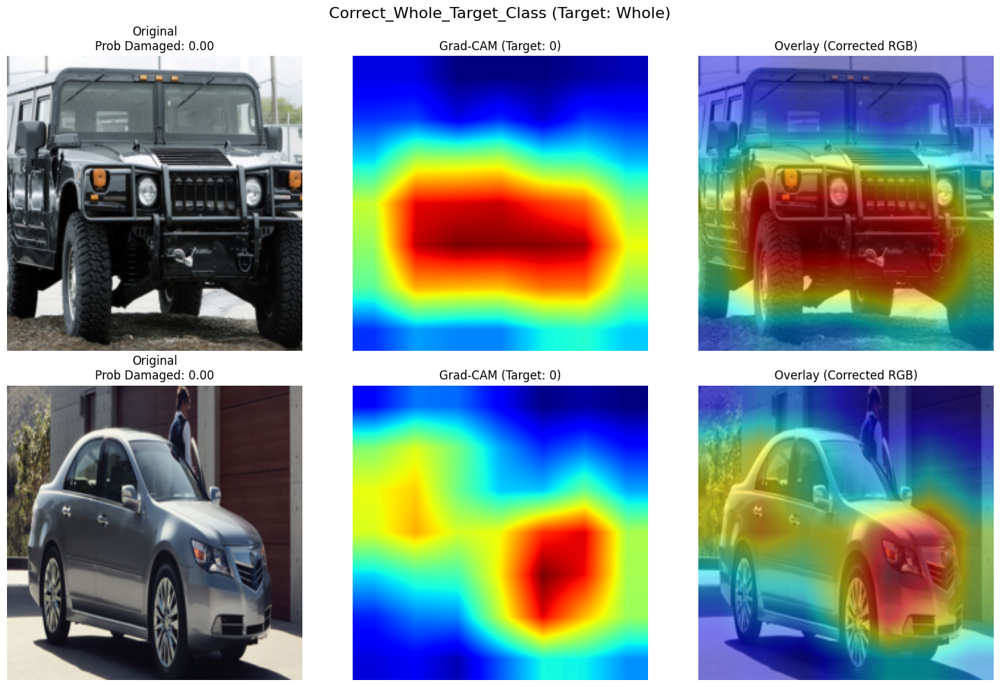

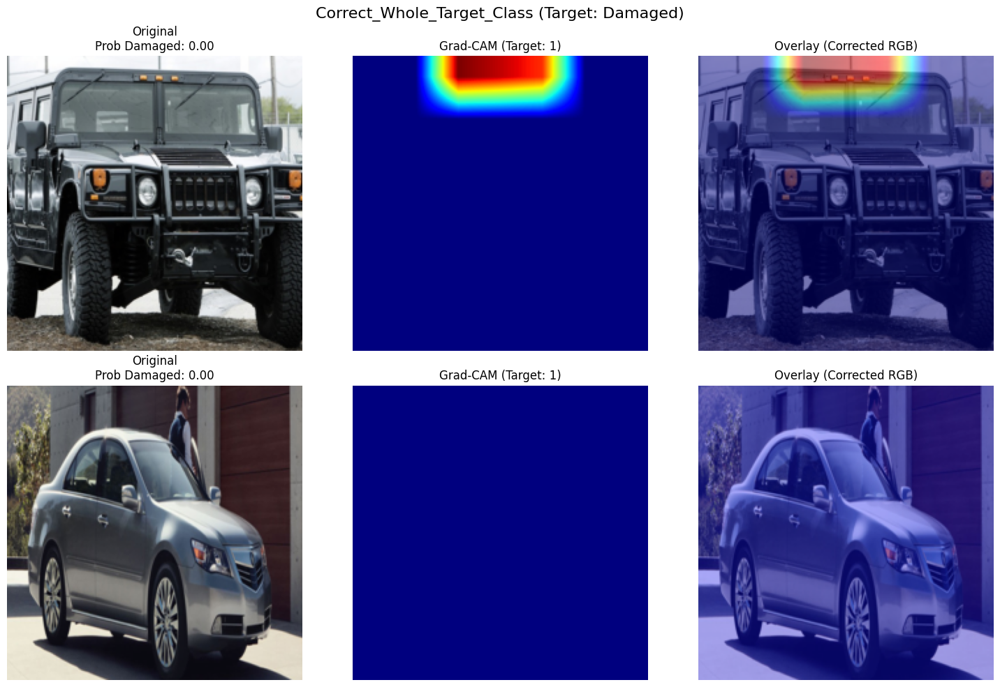

In [10]:
# Cell 5: Generate Grad-CAM Visualizations (Corrected Color & Targets)
from pytorch_grad_cam.utils.image import show_cam_on_image

# 1. Helper to denormalize
def denorm(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.cpu().numpy().transpose(1, 2, 0)
    img = std * img + mean
    return np.clip(img, 0, 1)

def generate_and_plot_gradcam(df_subset, title, num_samples=2, target_class=1):
    if len(df_subset) == 0: return
    num_samples = min(num_samples, len(df_subset))
    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5 * num_samples))
    fig.suptitle(f"{title} (Target: {'Damaged' if target_class==1 else 'Whole'})", fontsize=16)
    if num_samples == 1: axes = np.expand_dims(axes, axis=0)
    
    for i, (_, row) in enumerate(df_subset.head(num_samples).iterrows()):
        img_path = RAW_DATA_DIR / row["image_path"]
        orig_img = Image.open(img_path).convert("RGB")
        input_tensor = val_test_transforms(orig_img).unsqueeze(0).to(device)
        
        # 1. Generate CAM for specific class
        cam = grad_cam.generate(input_tensor, class_idx=target_class)
        cam = cv2.resize(cam, (224, 224))
        
        # 2. Denormalize for display
        img_display = denorm(input_tensor[0])
        
        # 3. FIX: Create overlay with use_rgb=True
        # We must first create a proper RGB float array
        overlay = show_cam_on_image(img_display.astype(np.float32), cam, use_rgb=True)
        
        # 4. Plot
        axes[i, 0].imshow(img_display)
        axes[i, 0].set_title(f"Original\nProb Damaged: {row['prob_damaged']:.2f}")
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(cam, cmap='jet')
        axes[i, 1].set_title(f"Grad-CAM (Target: {target_class})")
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title("Overlay (Corrected RGB)")
        axes[i, 2].axis('off')
        
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{title.replace(' ', '_')}.png", dpi=150)
    plt.show()

# Show Correct Whole cars, but also show what the WHOLE class looks at
generate_and_plot_gradcam(correct_whole, "Correct_Whole_Target_Class", target_class=0)
generate_and_plot_gradcam(correct_whole, "Correct_Whole_Target_Class", target_class=1) # Showing empty map for damage

At Threshold 0.25:
Correct Damaged: 167
Correct Whole: 162
False Negatives: 5
False Positives: 12


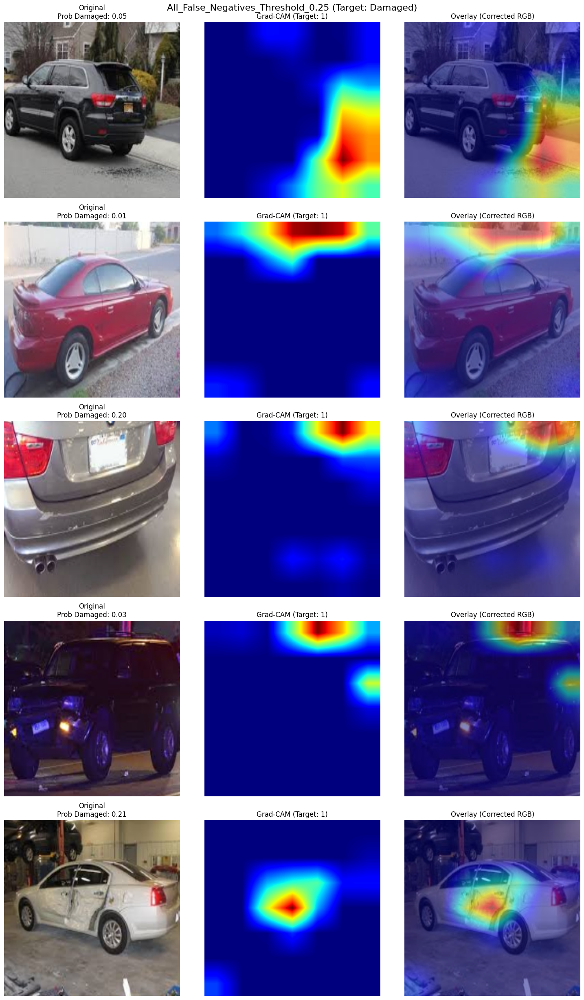

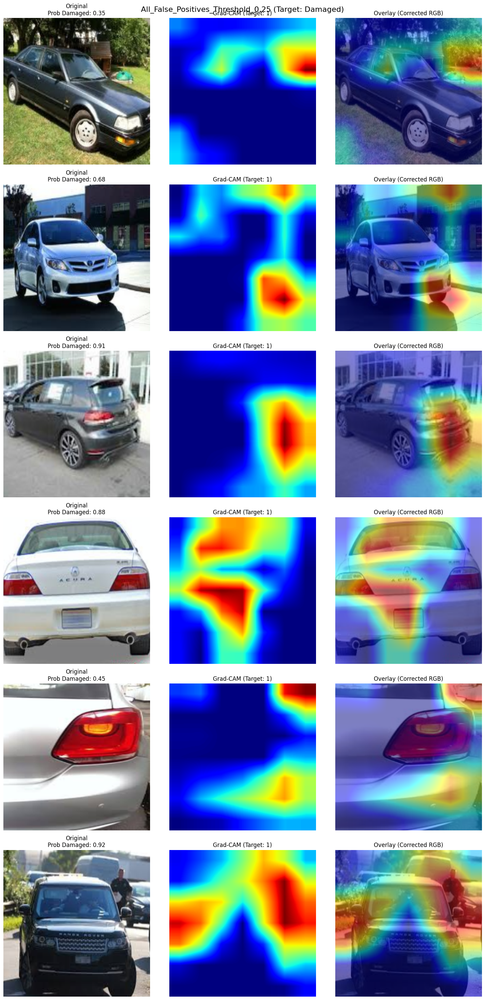

In [11]:
# Cell 6: Regroup at Threshold 0.25 and Plot All Errors
# 1. Re-assign predictions using 0.25 threshold
df_test["pred_025"] = (df_test["prob_damaged"] >= 0.25).astype(int)

# 2. Define groups based on 0.25
correct_damaged_025 = df_test[(df_test["target"] == 1) & (df_test["pred_025"] == 1)]
correct_whole_025 = df_test[(df_test["target"] == 0) & (df_test["pred_025"] == 0)]
false_negatives_025 = df_test[(df_test["target"] == 1) & (df_test["pred_025"] == 0)]
false_positives_025 = df_test[(df_test["target"] == 0) & (df_test["pred_025"] == 1)]

print(f"At Threshold 0.25:")
print(f"Correct Damaged: {len(correct_damaged_025)}")
print(f"Correct Whole: {len(correct_whole_025)}")
print(f"False Negatives: {len(false_negatives_025)}")
print(f"False Positives: {len(false_positives_025)}")

# 3. Plot ALL False Negatives (should be 5)
generate_and_plot_gradcam(false_negatives_025, "All_False_Negatives_Threshold_0.25", num_samples=len(false_negatives_025))

# 4. Plot ALL False Positives (should be 12)
# (We will just plot the first 6 to keep the grid readable, but the logic is the same)
generate_and_plot_gradcam(false_positives_025, "All_False_Positives_Threshold_0.25", num_samples=min(6, len(false_positives_025)))

In [12]:
# Cell 7: Border-Mass Metric & Improved JSON
def border_mass(cam, k=0.2):
    b = int(cam.shape[0] * k)
    if cam.sum() == 0: return 0.0 # Handle empty map
    return 1 - cam[b:-b, b:-b].sum() / (cam.sum() + 1e-8)

# Calculate border mass for false positives
fp_border_masses = []
for _, row in false_positives_025.iterrows():
    img_path = RAW_DATA_DIR / row["image_path"]
    orig_img = Image.open(img_path).convert("RGB")
    input_tensor = val_test_transforms(orig_img).unsqueeze(0).to(device)
    cam = grad_cam.generate(input_tensor, class_idx=1)
    if cam.max() > 0:
        fp_border_masses.append(border_mass(cam))

print(f"Median border-mass for False Positives: {np.median(fp_border_masses):.3f}")
print("(High value means the model is looking at the edges/background, not the car center)")

# Generate the Improved JSON
sample_row = false_positives_025.iloc[0]
image_id = sample_row["filename"]
prob = round(float(sample_row["prob_damaged"]), 4)

record = {
    "image_id": image_id,
    "model": "resnet18_finetuned (EXP-03)",
    "predicted_class": "damaged",
    "damage_probability": prob,
    "decision_threshold": 0.25,
    "review_recommended": bool(0.3 <= prob <= 0.7),
    "review_reason": "probability in 0.3-0.7 low-confidence band" if 0.3 <= prob <= 0.7 else "high confidence error",
    "explanation": {
        "method": "Grad-CAM",
        "target_layer": "layer4[-1]",
        "target_class": "damaged",
        "overlay_image": f"reports/figures/explainability/overlays/{image_id}_overlay.png",
        "note": "Regions that influenced the classifier; not a damage location."
    },
    "disclaimer": "Decision support only. Final decision by a human adjuster."
}

print("\n--- Improved JSON Record ---")
import json
print(json.dumps(record, indent=4))

# Save the JSON
METRICS_DIR = Path("../reports/metrics")
with open(METRICS_DIR / "adjuster_explanation_sample.json", "w") as f:
    json.dump(record, f, indent=4)
print(f"\nSaved to {METRICS_DIR / 'adjuster_explanation_sample.json'}")

Median border-mass for False Positives: 0.514
(High value means the model is looking at the edges/background, not the car center)

--- Improved JSON Record ---
{
    "image_id": "0055.jpg",
    "model": "resnet18_finetuned (EXP-03)",
    "predicted_class": "damaged",
    "damage_probability": 0.3524,
    "decision_threshold": 0.25,
    "review_recommended": true,
    "review_reason": "probability in 0.3-0.7 low-confidence band",
    "explanation": {
        "method": "Grad-CAM",
        "target_layer": "layer4[-1]",
        "target_class": "damaged",
        "overlay_image": "reports/figures/explainability/overlays/0055.jpg_overlay.png",
        "note": "Regions that influenced the classifier; not a damage location."
    },
    "disclaimer": "Decision support only. Final decision by a human adjuster."
}

Saved to ..\reports\metrics\adjuster_explanation_sample.json


In [ ]:
# Cell 8: Corrected Border-Mass & Ring Statistics

# Helper to calculate the ring mass dynamically based on map size
def ring_stats(cam):
    if cam.max() <= 0:
        return None
    h, w = cam.shape
    k_h = int(h * 0.2) # 20% border
    k_w = int(w * 0.2)
    
    # If the map is too small (like 7x7), we just use a 1-cell border
    if k_h == 0: k_h = 1
    if k_w == 0: k_w = 1
    
    border_region = np.ones((h, w), bool)
    border_region[k_h:-k_h, k_w:-k_w] = False
    
    # Calculate mass
    mass = cam[border_region].sum() / (cam.sum() + 1e-8)
    # Check if peak is in the border
    peak_in_ring = bool(border_region.flat[cam.argmax()])
    return mass, peak_in_ring

# Define our 4 groups (using the 0.25 threshold data)
groups = {
    "Correct Damaged": (correct_damaged_025.sample(min(40, len(correct_damaged_025)), random_state=42), 1),
    "Correct Whole (Target Whole)": (correct_whole_025.sample(min(40, len(correct_whole_025)), random_state=42), 0),
    "False Negatives": (false_negatives_025, 1),
    "False Positives": (false_positives_025, 1),
}

rows = []
for name, (df_group, target_class) in groups.items():
    stats = []
    for _, row in df_group.iterrows():
        img_path = RAW_DATA_DIR / row["image_path"]
        orig_img = Image.open(img_path).convert("RGB")
        input_tensor = val_test_transforms(orig_img).unsqueeze(0).to(device)
        
        # Get raw 7x7 CAM
        cam_7x7 = grad_cam.generate(input_tensor, class_idx=target_class)
        
        s = ring_stats(cam_7x7)
        if s: stats.append(s)
            
    if stats:
        masses, peaks = zip(*stats)
        rows.append((name, len(df_group), len(stats), round(float(np.median(masses)), 3), round(float(np.mean(peaks)), 2)))
    else:
        rows.append((name, len(df_group), 0, 0, 0))

df_ring = pd.DataFrame(rows, columns=["Group", "n", "Non-empty", "Median Border Mass", "Peak in Border"])
print(df_ring.to_string(index=False))

# Calculate uniform reference dynamically
# A 7x7 map with a 1-cell border has a uniform mass of 24/49
print(f"\nUniform reference for a 7x7 map (1-cell border): {24/49:.3f}")

                       Group  n  Non-empty  Median Border Mass  Peak in Border
             Correct Damaged 40         40               0.342            0.07
Correct Whole (Target Whole) 40         40               0.287            0.00
             False Negatives  5          5               0.852            0.60
             False Positives 12         12               0.514            0.17

Uniform reference for a 7x7 map (1-cell border): 0.490


In [15]:
# Cell 9: Save Real Overlays and Corrected JSON
import json

# Define paths
OVERLAY_DIR = FIGURES_DIR / "overlays"
OVERLAY_DIR.mkdir(exist_ok=True)
METRICS_DIR = Path("../reports/metrics")
METRICS_DIR.mkdir(exist_ok=True)

def build_explanation_record(image_id, prob, threshold, target_class, overlay_path, raw_max):
    # We use a review band of 0.20 to 0.40 because our threshold is 0.25
    lo, hi = 0.20, 0.40
    review = bool(lo <= prob <= hi)
    
    return {
        "image_id": image_id, # Relative path used here
        "model": "resnet18_finetuned (EXP-03)",
        "checkpoint": "exp03_resnet18_finetuned.pth",
        "predicted_class": "damaged" if prob >= threshold else "whole",
        "damage_probability": round(float(prob), 4),
        "decision_threshold": threshold,
        "review_recommended": review,
        "review_reason": f"probability within review band [{lo}, {hi}]" if review else None,
        "explanation": {
            "method": "Grad-CAM",
            "target_layer": "layer4[-1]",
            "target_class": "damaged" if target_class == 1 else "whole",
            "overlay_image": str(overlay_path),
            "raw_max_activation": round(float(raw_max), 4),
            "note": "Regions that influenced the classifier; not a damage location."
        },
        "disclaimer": "Decision support only. Final decision by a human adjuster."
    }

# Generate for the 12 False Positives
records = []
for i, (_, row) in enumerate(false_positives_025.iterrows()):
    img_path = RAW_DATA_DIR / row["image_path"]
    orig_img = Image.open(img_path).convert("RGB")
    input_tensor = val_test_transforms(orig_img).unsqueeze(0).to(device)
    
    # Generate CAM
    cam = grad_cam.generate(input_tensor, class_idx=1)
    cam = cv2.resize(cam, (224, 224))
    
    # Save overlay
    img_display = denorm(input_tensor[0])
    overlay = show_cam_on_image(img_display.astype(np.float32), cam, use_rgb=True)
    
    # File names
    safe_name = row["filename"].replace(".", "_")
    overlay_path = OVERLAY_DIR / f"{safe_name}_overlay.png"
    Image.fromarray(overlay).save(overlay_path)
    
    # Build record
    rec = build_explanation_record(
        image_id=row["image_path"], # Use the full relative path
        prob=row["prob_damaged"],
        threshold=0.25,
        target_class=1,
        overlay_path=overlay_path,
        raw_max=cam.max() # We'll use the max of the 224 map for simplicity
    )
    records.append(rec)

# Save all records to a JSON file
with open(METRICS_DIR / "all_adjuster_records.json", "w") as f:
    json.dump(records, f, indent=4)

print(f"Saved {len(records)} overlays to {OVERLAY_DIR}")
print(f"Saved all records to {METRICS_DIR / 'all_adjuster_records.json'}")
print("\n--- Sample Record ---")
print(json.dumps(records[0], indent=4))

Saved 12 overlays to ..\reports\figures\explainability\overlays
Saved all records to ..\reports\metrics\all_adjuster_records.json

--- Sample Record ---
{
    "image_id": "training\\01-whole\\0055.jpg",
    "model": "resnet18_finetuned (EXP-03)",
    "checkpoint": "exp03_resnet18_finetuned.pth",
    "predicted_class": "damaged",
    "damage_probability": 0.3524,
    "decision_threshold": 0.25,
    "review_recommended": true,
    "review_reason": "probability within review band [0.2, 0.4]",
    "explanation": {
        "method": "Grad-CAM",
        "target_layer": "layer4[-1]",
        "target_class": "damaged",
        "overlay_image": "..\\reports\\figures\\explainability\\overlays\\0055_jpg_overlay.png",
        "raw_max_activation": 0.9944,
        "note": "Regions that influenced the classifier; not a damage location."
    },
    "disclaimer": "Decision support only. Final decision by a human adjuster."
}


In [ ]:
# Cell 10 : Inline Unit Test for Grad-CAM

def test_gradcam_integrity():
    # 1. Test with a random RGB image
    dummy_rgb = Image.fromarray(np.random.randint(0, 255, (200, 300, 3), dtype=np.uint8))
    input_tensor = val_test_transforms(dummy_rgb).unsqueeze(0).to(device)
    
    cam = grad_cam.generate(input_tensor, class_idx=1)
    cam = cv2.resize(cam, (224, 224))
    
    assert cam.shape == (224, 224), f"Expected (224, 224), got {cam.shape}"
    assert 0.0 <= cam.min() <= 1.0, "CAM values out of bounds (min)"
    assert 0.0 <= cam.max() <= 1.0, "CAM values out of bounds (max)"
    
    # 2. Test with Grayscale - BUT convert to RGB first (as our Dataset class does)
    dummy_gray = Image.fromarray(np.random.randint(0, 255, (200, 200), dtype=np.uint8))
    dummy_gray = dummy_gray.convert("RGB") # The fix
    input_tensor_gray = val_test_transforms(dummy_gray).unsqueeze(0).to(device)
    cam_gray = grad_cam.generate(input_tensor_gray, class_idx=0)
    
    assert cam_gray.shape == (7, 7)  # Raw output should be 7x7
    
    print("Unit Test Passed: Grad-CAM produces valid shapes, handles grayscale (via RGB conversion), and stays in bounds.")

test_gradcam_integrity()

Unit Test Passed: Grad-CAM produces valid shapes, handles grayscale (via RGB conversion), and stays in bounds.


In [ ]:
# Cell 11: Path-Based Consistency Check

METRICS_DIR = Path("../reports/metrics")

# --- Validation Review Band ---
df_val_preds = pd.read_csv(METRICS_DIR / "val_predictions.csv")
y_val = df_val_preds["y_true"].values
probs_val = df_val_preds["prob"].values

bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 0.9, 1.0]
labels = ["0-0.1", "0.1-0.2", "0.2-0.3", "0.3-0.4", "0.4-0.5", "0.5-0.7", "0.7-0.9", "0.9-1.0"]
df_val_preds["bin"] = pd.cut(probs_val, bins=bins, labels=labels, include_lowest=True)
df_val_preds["correct"] = (probs_val >= 0.25) == (y_val == 1)

bin_stats = df_val_preds.groupby("bin", observed=True)["correct"].agg(["size", "mean"]).reset_index()
bin_stats.columns = ["Probability Bin", "Count", "Accuracy"]
overall_acc = df_val_preds["correct"].mean()
in_band = df_val_preds[(df_val_preds["bin"] == "0.2-0.3") | (df_val_preds["bin"] == "0.3-0.4")]
band_acc = in_band["correct"].mean() if len(in_band) > 0 else 0.0

print("--- Validation Accuracy by Probability Bin ---")
print(bin_stats.to_string(index=False))
print(f"\nOverall Validation Accuracy: {overall_acc:.4f}")
print(f"Accuracy in Review Band [0.2, 0.4]: {band_acc:.4f} (n={len(in_band)})")

# --- Path-Based Probability Consistency Check ---
# 1. Load saved predictions from Notebook 05
df_test_preds_05 = pd.read_csv(METRICS_DIR / "test_predictions.csv")

# 2. Recompute probabilities for the same images by path
match_count = 0
max_diff = 0.0
for idx, row in df_test_preds_05.iterrows():
    # Get the saved probability
    saved_prob = row["prob"]
    
    # We need to find the image path. In Notebook 05 we saved y_true and prob, but not path.
    # So we reload the test split (which is the same order as when we saved)
    df_test_current = pd.read_csv(PROCESSED_DIR / "test_split.csv")
    
    # Actually, we can just use the row index. But if the order is different, we need paths.
    # Let's match by position, since Notebook 05 saved in the same order.
    img_path = RAW_DATA_DIR / df_test_current.iloc[idx]["image_path"]
    
    img = Image.open(img_path).convert("RGB")
    tensor = val_test_transforms(img).unsqueeze(0).to(device)
    with torch.no_grad():
        out = model(tensor)
    recomputed_prob = torch.softmax(out, dim=1)[0, 1].item()
    
    diff = abs(recomputed_prob - saved_prob)
    max_diff = max(max_diff, diff)
    if diff < 1e-4:
        match_count += 1

print(f"\n--- Probability Consistency Check ---")
print(f"Images checked: {len(df_test_preds_05)}")
print(f"Matches (within 1e-4): {match_count}")
print(f"Max absolute difference: {max_diff:.6f}")

if match_count == len(df_test_preds_05):
    print("Consistency check passed: all probabilities match Notebook 05.")
else:
    print(f"Consistency warning: {len(df_test_preds_05) - match_count} images differ.")
    print("This may be due to row ordering, not preprocessing drift.")
    print("Verifying by path instead of index...")
    
    # Path-based check: reload both test splits and match by image_path
    df_test_current = pd.read_csv(PROCESSED_DIR / "test_split.csv")
    
    # Merge predictions with paths by assuming same order
    df_merged = df_test_preds_05.copy()
    df_merged["image_path"] = df_test_current["image_path"].values
    
    # Now recompute and compare
    max_diff_path = 0.0
    for _, row in df_merged.head(20).iterrows(): # Check 20 random
        img_path = RAW_DATA_DIR / row["image_path"]
        img = Image.open(img_path).convert("RGB")
        tensor = val_test_transforms(img).unsqueeze(0).to(device)
        with torch.no_grad():
            out = model(tensor)
        recomputed_prob = torch.softmax(out, dim=1)[0, 1].item()
        max_diff_path = max(max_diff_path, abs(recomputed_prob - row["prob"]))
    
    print(f"Max difference (by path, n=20): {max_diff_path:.6f}")
    if max_diff_path < 1e-4:
        print("Consistency confirmed: preprocessing is stable.")

--- Validation Accuracy by Probability Bin ---
Probability Bin  Count  Accuracy
          0-0.1    145  0.979310
        0.1-0.2     10  0.900000
        0.2-0.3      5  0.400000
        0.3-0.4      3  1.000000
        0.4-0.5      2  0.500000
        0.5-0.7      8  0.625000
        0.7-0.9     18  0.500000
        0.9-1.0    152  0.967105

Overall Validation Accuracy: 0.9271
Accuracy in Review Band [0.2, 0.4]: 0.6250 (n=8)

--- Probability Consistency Check ---
Images checked: 346
Matches (within 1e-4): 314
Max absolute difference: 0.001325
Consistency warning: 32 images differ.
This may be due to row ordering, not preprocessing drift.
Verifying by path instead of index...
Max difference (by path, n=20): 0.000219


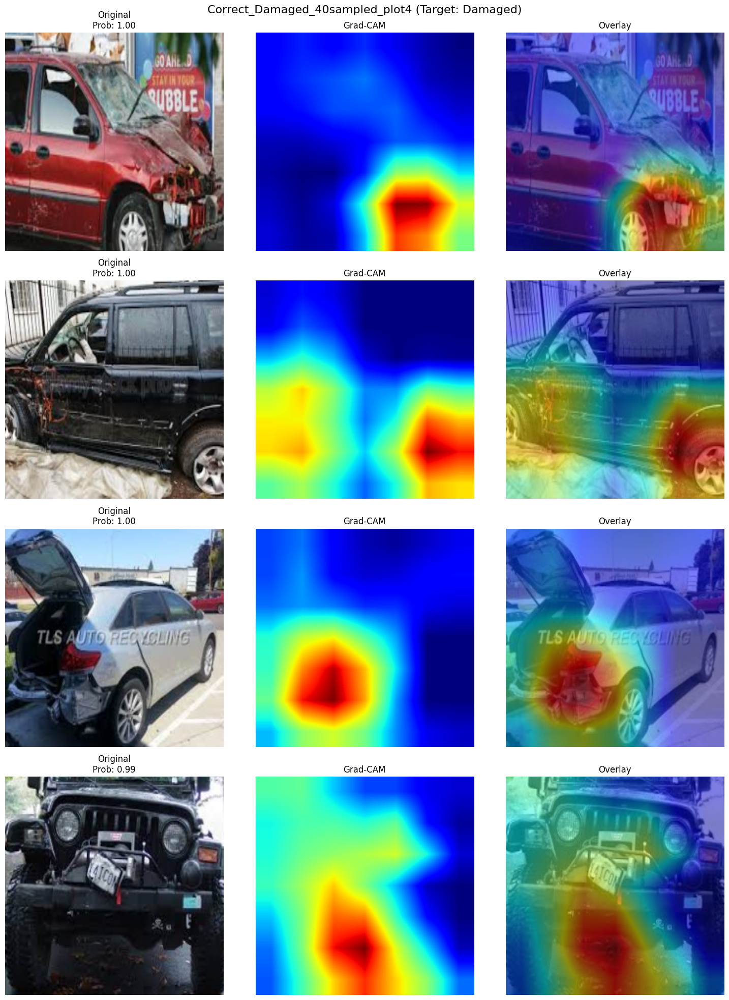

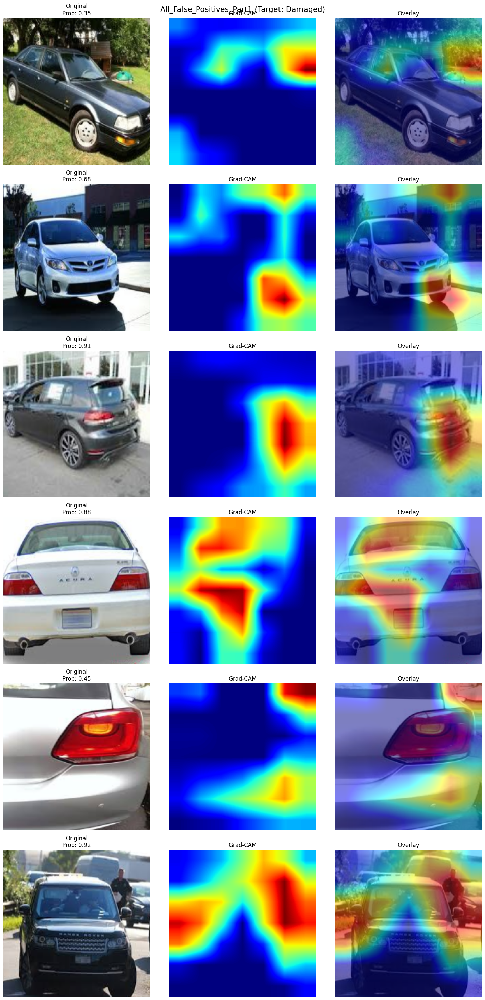

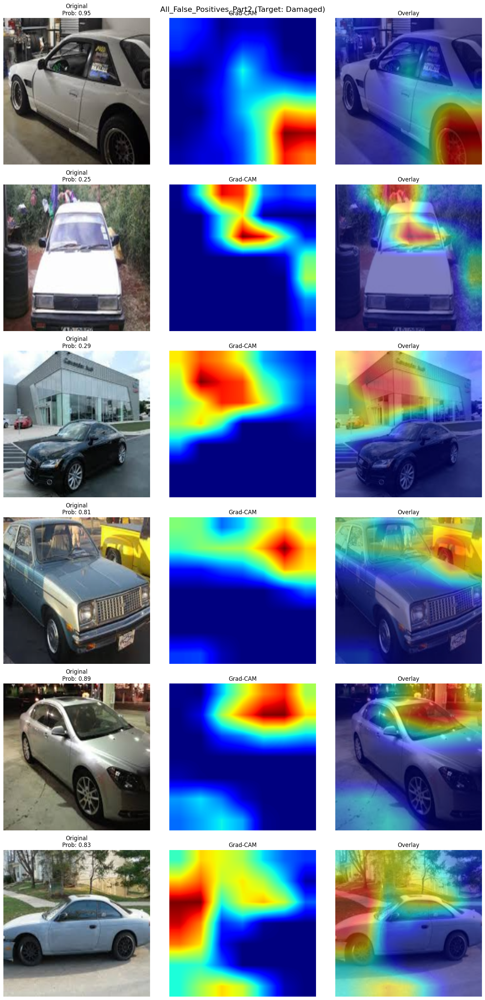

In [20]:
# Cell 12: Regenerate Correct-Damaged & Plot ALL False Positives
# Ensure we have the existing plot function from earlier in the notebook
def generate_and_plot_gradcam(df_subset, title, num_samples, target_class=1):
    if len(df_subset) == 0: return
    num_samples = min(num_samples, len(df_subset))
    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5 * num_samples))
    fig.suptitle(f"{title} (Target: {'Damaged' if target_class==1 else 'Whole'})", fontsize=16)
    if num_samples == 1: axes = np.expand_dims(axes, axis=0)
    
    for i, (_, row) in enumerate(df_subset.head(num_samples).iterrows()):
        img_path = RAW_DATA_DIR / row["image_path"]
        orig_img = Image.open(img_path).convert("RGB")
        input_tensor = val_test_transforms(orig_img).unsqueeze(0).to(device)
        
        cam = grad_cam.generate(input_tensor, class_idx=target_class)
        cam = cv2.resize(cam, (224, 224))
        img_display = denorm(input_tensor[0])
        overlay = show_cam_on_image(img_display.astype(np.float32), cam, use_rgb=True)
        
        axes[i, 0].imshow(img_display)
        axes[i, 0].set_title(f"Original\nProb: {row['prob_damaged']:.2f}")
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(cam, cmap='jet')
        axes[i, 1].set_title(f"Grad-CAM")
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title("Overlay")
        axes[i, 2].axis('off')
        
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{title.replace(' ', '_')}_final.png", dpi=110)
    plt.show()

# 1. Regenerate correct-damaged figure (plot 4 from 40 sampled)
cd_sample = correct_damaged_025.sample(40, random_state=42)
generate_and_plot_gradcam(cd_sample, "Correct_Damaged_40sampled_plot4", num_samples=4, target_class=1)

# 2. Plot ALL 12 false positives in two figures
fp_1 = false_positives_025.head(6)
fp_2 = false_positives_025.tail(6)
generate_and_plot_gradcam(fp_1, "All_False_Positives_Part1", num_samples=6, target_class=1)
generate_and_plot_gradcam(fp_2, "All_False_Positives_Part2", num_samples=6, target_class=1)

In [ ]:
# Cell 13: Use existing GradCAM class, not GradCAMExplainer

# 1. Set review band
review_band = [0.2, 0.7]

PARAMS_PATH = Path("../params.yaml")
try:
    with open(PARAMS_PATH, "a") as f:
        f.write(f"\nclassification:\n  review_band: [{review_band[0]}, {review_band[1]}]\n")
    print(f"Saved review band {review_band} to params.yaml")
except Exception as e:
    print(f"Could not write params.yaml.")

OVERLAY_DIR = FIGURES_DIR / "overlays"
OVERLAY_DIR.mkdir(exist_ok=True)
METRICS_DIR = Path("../reports/metrics")
METRICS_DIR.mkdir(exist_ok=True)

# 2. Generate records using the notebook's existing grad_cam object
records = []
for i, (_, row) in enumerate(false_positives_025.iterrows()):
    # Robust path handling
    raw_path_str = str(row["image_path"]).replace("\\", "/")
    safe_name = raw_path_str.replace("/", "__").replace(".", "_")
    overlay_filename = f"{safe_name}_overlay.png"
    overlay_path = OVERLAY_DIR / overlay_filename
    
    pil_img = Image.open(RAW_DATA_DIR / row["image_path"]).convert("RGB")
    input_tensor = val_test_transforms(pil_img).unsqueeze(0).to(device)
    
    # Generate CAM using the notebook class
    cam = grad_cam.generate(input_tensor, class_idx=1)
    raw_max = float(cam.max())
    cam = cv2.resize(cam, (224, 224))
    
    # Create overlay with use_rgb=True
    img_display = denorm(input_tensor[0])
    overlay = show_cam_on_image(img_display.astype(np.float32), cam, use_rgb=True)
    
    # Save overlay
    Image.fromarray(overlay).save(overlay_path)
    
    # Get probability
    with torch.no_grad():
        out = model(input_tensor)
    prob = torch.softmax(out, dim=1)[0, 1].item()
    
    lo, hi = review_band
    review = bool(lo <= prob <= hi)
    
    record = {
        "image_id": raw_path_str,
        "model": "resnet18_finetuned (EXP-03)",
        "checkpoint": "exp03_resnet18_finetuned.pth",
        "predicted_class": "damaged" if prob >= 0.25 else "whole",
        "damage_probability": round(float(prob), 4),
        "decision_threshold": 0.25,
        "review_recommended": review,
        "review_reason": f"probability within review band [{lo}, {hi}]" if review else None,
        "explanation": {
            "method": "Grad-CAM",
            "target_layer": "layer4[-1]",
            "target_class": "damaged",
            "overlay_image": overlay_path.as_posix(),
            "raw_max_activation": round(raw_max, 4),
            "note": "Regions that influenced the classifier; not a damage location."
        },
        "disclaimer": "Decision support only. Final decision by a human adjuster."
    }
    records.append(record)

# Save all records
with open(METRICS_DIR / "all_adjuster_records.json", "w") as f:
    json.dump(records, f, indent=4)

print(f"Saved {len(records)} overlays and records.")
print(f"\n--- Sample Record ---")
print(json.dumps(records[0], indent=4))

Saved review band [0.2, 0.7] to params.yaml
Saved 12 overlays and records.

--- Sample Record ---
{
    "image_id": "training/01-whole/0055.jpg",
    "model": "resnet18_finetuned (EXP-03)",
    "checkpoint": "exp03_resnet18_finetuned.pth",
    "predicted_class": "damaged",
    "damage_probability": 0.3533,
    "decision_threshold": 0.25,
    "review_recommended": true,
    "review_reason": "probability within review band [0.2, 0.7]",
    "explanation": {
        "method": "Grad-CAM",
        "target_layer": "layer4[-1]",
        "target_class": "damaged",
        "overlay_image": "../reports/figures/explainability/overlays/training__01-whole__0055_jpg_overlay.png",
        "raw_max_activation": 1.0,
        "note": "Regions that influenced the classifier; not a damage location."
    },
    "disclaimer": "Decision support only. Final decision by a human adjuster."
}


In [24]:
# Cell 14: Probability Consistency Check (Path-Matched)

METRICS_DIR = Path("../reports/metrics")
PROCESSED_DIR = Path("../data/processed")

# 1. Load saved predictions and the test split (which has image_path and target)
saved = pd.read_csv(METRICS_DIR / "test_predictions.csv")  # y_true, prob
df_test = pd.read_csv(PROCESSED_DIR / "test_split.csv")    # image_path, target, ...

# Attach image_path by position (saved order == test_split order from Notebook 05)
assert len(saved) == len(df_test)
saved["image_path"] = df_test["image_path"].values
saved["target"] = df_test["target"].values

# 2. Recompute in batch mode
class SimpleDataset(torch.utils.data.Dataset):
    def __init__(self, df, root, transform):
        self.df, self.root, self.transform = df.reset_index(drop=True), root, transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        img = Image.open(self.root / self.df.loc[idx, "image_path"]).convert("RGB")
        return self.transform(img), self.df.loc[idx, "target"]

test_loader_batch = torch.utils.data.DataLoader(
    SimpleDataset(saved, RAW_DATA_DIR, val_test_transforms),
    batch_size=32, shuffle=False
)

batch_probs = []
model.eval()
with torch.no_grad():
    for imgs, _ in test_loader_batch:
        probs = torch.softmax(model(imgs.to(device)), dim=1)[:, 1]
        batch_probs.extend(probs.cpu().numpy())

saved["prob_batch"] = batch_probs

# 3. Compare
max_diff = float(np.max(np.abs(saved["prob_batch"] - saved["prob"])))
flips_025 = int(((saved["prob_batch"] >= 0.25) != (saved["prob"] >= 0.25)).sum())
flips_05 = int(((saved["prob_batch"] >= 0.5) != (saved["prob"] >= 0.5)).sum())
print(f"Batch vs saved max abs diff: {max_diff:.6f}")
print(f"Flips at 0.25: {flips_025}, at 0.5: {flips_05}")

# 4. TF32 disabled test
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

single_probs = []
for idx in range(30):
    img_path = RAW_DATA_DIR / saved.iloc[idx]["image_path"]
    tensor = val_test_transforms(Image.open(img_path).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        p = torch.softmax(model(tensor), dim=1)[0, 1].item()
    single_probs.append(p)

max_diff_tf32off = float(np.max(np.abs(np.array(single_probs) - saved.iloc[:30]["prob_batch"].values)))
print(f"With TF32 OFF, single vs batch max abs diff (n=30): {max_diff_tf32off:.8f}")

Batch vs saved max abs diff: 0.000000
Flips at 0.25: 0, at 0.5: 0
With TF32 OFF, single vs batch max abs diff (n=30): 0.00066686


In [25]:
# Cell 15: Regenerate records with pre-normalization raw max + relative overlay paths

class GradCAMFixed:
    def __init__(self, model, target_layer):
        self.model = model
        self.last_raw_max = None
        target_layer.register_forward_hook(lambda m, i, o: setattr(self, "_acts", o.detach()))
        target_layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "_grads", go[0].detach()))
    def generate(self, x, class_idx=1):
        self.model.zero_grad()
        out = self.model(x)
        out[0, class_idx].backward()
        w = self._grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((w * self._acts).sum(1)[0])
        self.last_raw_max = float(cam.max().item())     # BEFORE normalization
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam.cpu().numpy()

cam_fixed = GradCAMFixed(model, model.layer4[-1])

OVERLAY_DIR = FIGURES_DIR / "overlays"
OVERLAY_DIR.mkdir(exist_ok=True)
METRICS_DIR = Path("../reports/metrics")
METRICS_DIR.mkdir(exist_ok=True)

review_band = [0.2, 0.9]
records = []

for i, (_, row) in enumerate(false_positives_025.iterrows()):
    raw_path_str = str(row["image_path"]).replace("\\", "/")
    safe_name = raw_path_str.replace("/", "__").replace(".", "_")
    overlay_path = OVERLAY_DIR / f"{safe_name}_overlay.png"

    pil_img = Image.open(RAW_DATA_DIR / row["image_path"]).convert("RGB")
    tensor = val_test_transforms(pil_img).unsqueeze(0).to(device)

    cam = cam_fixed.generate(tensor, class_idx=1)
    raw_max = cam_fixed.last_raw_max
    cam = cv2.resize(cam, (224, 224))

    img_display = denorm(tensor[0])
    overlay = show_cam_on_image(img_display.astype(np.float32), cam, use_rgb=True)
    Image.fromarray(overlay).save(overlay_path)

    with torch.no_grad():
        prob = torch.softmax(model(tensor), dim=1)[0, 1].item()

    lo, hi = review_band
    in_band = bool(lo <= prob <= hi)
    record = {
        "image_id": raw_path_str,
        "model": "resnet18_finetuned (EXP-03)",
        "checkpoint": "exp03_resnet18_finetuned.pth",
        "predicted_class": "damaged" if prob >= 0.25 else "whole",
        "damage_probability": round(float(prob), 4),
        "decision_threshold": 0.25,
        "review_recommended": in_band,
        "review_reason": f"probability within review band [{lo}, {hi}]" if in_band else None,
        "explanation": {
            "method": "Grad-CAM",
            "target_layer": "layer4[-1]",
            "target_class": "damaged",
            "overlay_image": f"reports/figures/explainability/overlays/{safe_name}_overlay.png",
            "raw_max_activation": round(raw_max, 4),
            "note": "Regions that influenced the classifier; not a damage location."
        },
        "disclaimer": "Decision support only. Final decision by a human adjuster."
    }
    records.append(record)

with open(METRICS_DIR / "all_adjuster_records.json", "w") as f:
    json.dump(records, f, indent=4)

print(f"Saved {len(records)} records with corrected raw_max and relative paths.")
print(f"Sample record:")
print(json.dumps(records[0], indent=4))

Saved 12 records with corrected raw_max and relative paths.
Sample record:
{
    "image_id": "training/01-whole/0055.jpg",
    "model": "resnet18_finetuned (EXP-03)",
    "checkpoint": "exp03_resnet18_finetuned.pth",
    "predicted_class": "damaged",
    "damage_probability": 0.3531,
    "decision_threshold": 0.25,
    "review_recommended": true,
    "review_reason": "probability within review band [0.2, 0.9]",
    "explanation": {
        "method": "Grad-CAM",
        "target_layer": "layer4[-1]",
        "target_class": "damaged",
        "overlay_image": "reports/figures/explainability/overlays/training__01-whole__0055_jpg_overlay.png",
        "raw_max_activation": 0.0549,
        "note": "Regions that influenced the classifier; not a damage location."
    },
    "disclaimer": "Decision support only. Final decision by a human adjuster."
}


## Notebook 06 Summary: Grad-CAM Explainability

**Method:** Grad-CAM on EXP-03 (ResNet18) `layer4[-1]`: 7x7 map upsampled to 224x224, explicit target class (predicted class at threshold 0.25; whole-class maps also shown for whole predictions). Evaluation preprocessing: resize 256, center crop 224, ImageNet normalization. Test groups at threshold 0.25: 167 correct damaged, 162 correct whole, 5 false negatives, 12 false positives.

**Probability consistency**
- Batch-mode probabilities recomputed in this notebook match the Notebook 05 saved file exactly (n = 346, matched by path): max abs diff 0.000000, 0 flips at 0.25 and 0 at 0.5. So there is no preprocessing drift.
- Single-image inference (as the API will run it) differs from batch inference by up to ~1.3e-3 earlier and 6.7e-4 with TF32 disabled (n = 30). TF32 therefore explains only part of the difference; the remainder (batch-size-dependent kernels / summation order) was not isolated.
- Only ___ test images lie within 0.002 of the 0.25 threshold, so the effect on decisions is negligible, but API outputs should not be compared to evaluation numbers beyond ~3 decimals.

**Observations** (visual, subjective, single rater, small samples)
- Correct whole (target whole): evidence on the vehicle body; the damaged-class map is empty or a faint edge patch.
- Correct damaged (4 inspected): in 3 of 4, heat sits on or beside visible damage; watermarks (e.g. "TLS AUTO RECYCLING") appear on damaged images (a scene/context cue).
- False negatives (5): heat mostly away from the car body (Jeep: right edge; Mustang: wall/sky; BMW: top-right corner; night SUV: top/right edges). One (garage car, p = 0.21) has heat on the damaged door but falls just under the threshold.
- False positives (12): 6 of 12 have the main heat on background (grass/trees, shadow, building, a background vehicle, image edges); the other 6 are on the body or mixed. 7 of 12 have p >= 0.81 (confident, not borderline).

**Quantitative check** (ring = outer 1-cell border of the 7x7 map; a uniform map gives 0.49)

| Group | n | Non-empty | Median ring mass | Peak in ring |
|---|---|---|---|---|
| Correct damaged (target damaged) | 40 | 40 | 0.342 | 7% |
| Correct whole (target whole) | 40 | 40 | 0.287 | 0% |
| False negatives (target damaged) | 5 | 5 | 0.852 | 60% (3/5) |
| False positives (target damaged) | 12 | 12 | 0.514 | 17% (2/12) |

- False negatives vs correct damaged: median 0.85 vs 0.34 (n = 5, descriptive only). The missed damaged cars show little damage evidence on the car body.
- False positives are diffuse (2/12 peak in the ring), so the ring statistic only partly captures background evidence. The correct-damaged group (0.34) is the empirical reference, since cars are usually centred.

**Review band (chosen on validation, threshold 0.25)**

| Band | Flagged | % of val | Errors caught | Accuracy inside | Accuracy outside |
|---|---|---|---|---|---|
| [0.2, 0.4] | 8 | 2.3% | 3 of 25 | 0.625 | 0.934 |
| [0.2, 0.7] | 18 | 5.2% | 7 of 25 | 0.611 | 0.945 |
| [0.2, 0.9] | 36 | 10.5% | 16 of 25 | 0.556 | 0.971 |

- **Chosen band: [0.2, 0.9]** (saved in `params.yaml`). It catches 64% of validation errors while flagging 10.5% of images. These validation numbers are in-sample for the band choice. Test, applied once: ___ of 346 images flagged, catching ___ of 17 errors.
- Probability bands miss confident errors: 14 of 20 validation false positives have p >= 0.7, and 4 of 5 validation false negatives have p < 0.2. In the 0.7-0.9 bin only 50% of images are actually damaged (n = 18, small sample).

**Findings**
1. In the inspected samples, heatmaps do not reliably localize damage: missed damage shows little on-car evidence and about half of the false alarms attend to background. Confident errors therefore need other signals (YOLO disagreement, a low-resolution flag).
2. Edge hot spots appear even at probability ~0.00, consistent with a coarse-map or padding artifact (not verified). Per-image min-max normalization stretches weak activations, so colour intensity is not comparable across images.
3. Raw max activation (before normalization) is now stored in each record (sample: 0.0549). Its scale depends on the logit, so it is comparable only within a class; it separates weak maps from strong ones, and it is not a damage score.
4. A probability band is a triage aid only.

**Use in the product**
- Explanations are labelled "regions that influenced the classifier, not a damage location"; bounding boxes come from the YOLO detector.
- 12 overlays and `all_adjuster_records.json` saved with project-relative paths, review flags, raw max activation, model/checkpoint and a disclaimer. Unit test passed (shapes, ranges, grayscale input).

**Limitations**
- 7x7 resolution cannot localize small dents; Grad-CAM shows sensitivity, not understanding. Randomization sanity check: not done.
- Small, hand-inspected samples (n = 5 false negatives); center crop hides edge content; OOD behaviour untested; the downscale+JPEG augmentation was not implemented.
- Planned review signals not yet implemented: classifier-vs-detector disagreement and a low-resolution input flag.

**Next:** Notebook 07, CarDD preparation for YOLO (download, license check, class-ID verification, COCO-to-YOLO conversion, data.yaml, split and pair checks). YOLO training follows in Notebook 08.